Using: D:\AgriVision\data\raw\Long 2023 Plant Path 999 photos\BrownRust1018.png
File exists: True


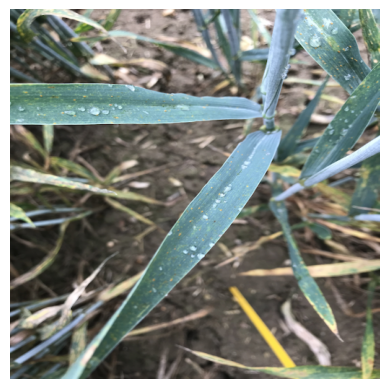

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# pick the first BrownRust image from the dataset
path = next(Path(r"D:\AgriVision\data\raw").rglob("BrownRust*.png"))
print("Using:", path)
print("File exists:", path.exists())

img = cv2.imread(str(path))
if img is None:
    raise FileNotFoundError("Could not read the image. Check the file name and folder.")

img = cv2.resize(img, (512, 512))
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(rgb)
plt.axis("off")
plt.show()

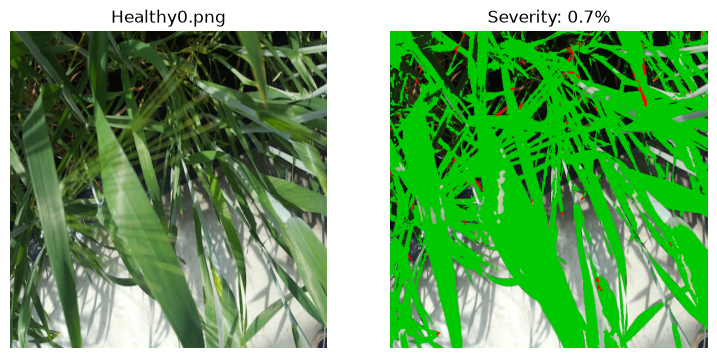

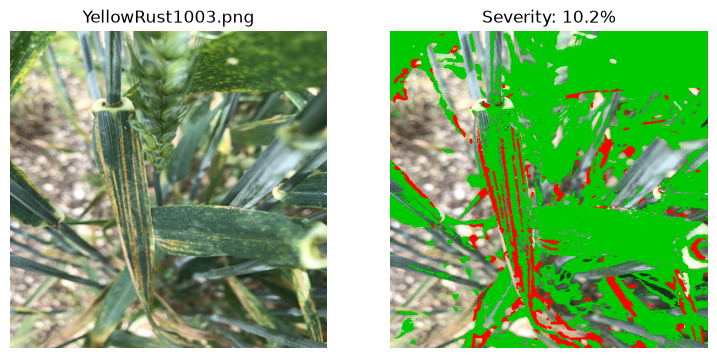

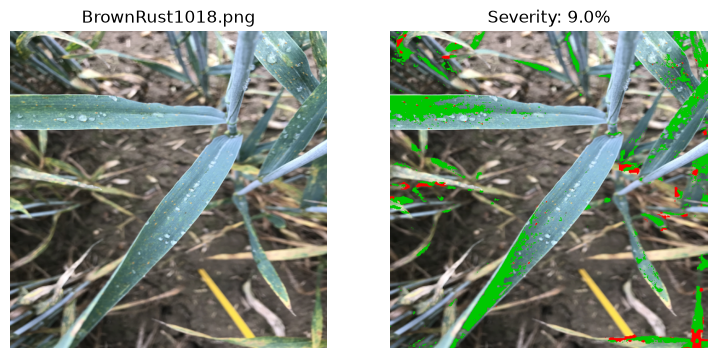

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

def estimate_severity(path):
    img = cv2.imread(str(path))
    img = cv2.resize(img, (512, 512))
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # 1. green pixels (healthy leaf tissue)
    green = cv2.inRange(hsv, (35, 60, 50), (85, 255, 255))

    # 2. leaf region: merge green pixels, keep only large blobs
    kernel = np.ones((15, 15), np.uint8)
    leaf = cv2.morphologyEx(green, cv2.MORPH_CLOSE, kernel)
    leaf = cv2.dilate(leaf, np.ones((9, 9), np.uint8))

    n, labels, stats, _ = cv2.connectedComponentsWithStats(leaf)
    leaf_mask = np.zeros_like(leaf)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] > 3000:
            leaf_mask[labels == i] = 255

    # 3. diseased = yellow/orange pixels, only inside the leaf region
    diseased = cv2.inRange(hsv, (10, 70, 90), (34, 255, 255))
    diseased = cv2.bitwise_and(diseased, leaf_mask)

    healthy_px = int(np.count_nonzero(green))
    diseased_px = int(np.count_nonzero(diseased))
    leaf_px = healthy_px + diseased_px
    severity = 100 * diseased_px / leaf_px if leaf_px else 0.0

    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    overlay = rgb.copy()
    overlay[green > 0] = (0, 200, 0)
    overlay[diseased > 0] = (255, 0, 0)
    return severity, rgb, overlay

def show(path):
    sev, rgb, overlay = estimate_severity(path)
    fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
    ax[0].imshow(rgb)
    ax[0].set_title(Path(path).name)
    ax[0].axis("off")
    ax[1].imshow(overlay)
    ax[1].set_title(f"Severity: {sev:.1f}%")
    ax[1].axis("off")
    plt.show()

RAW = Path(r"D:\AgriVision\data\raw")
for pattern in ["Healthy*.png", "YellowRust*.png", "BrownRust*.png"]:
    show(next(RAW.rglob(pattern)))

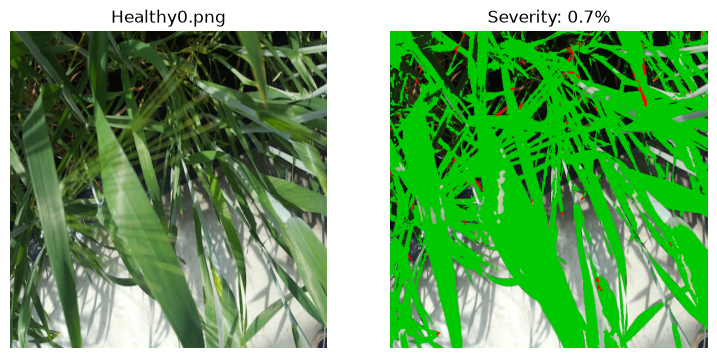

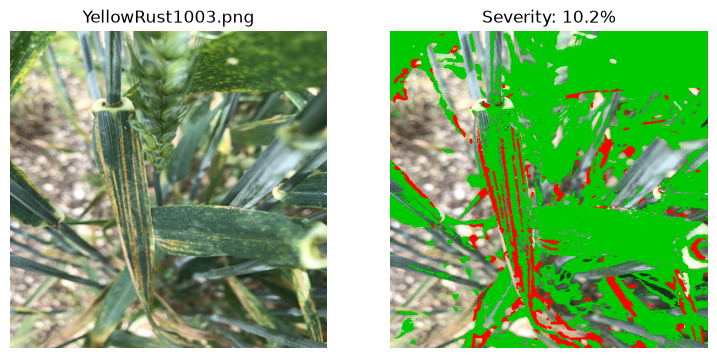

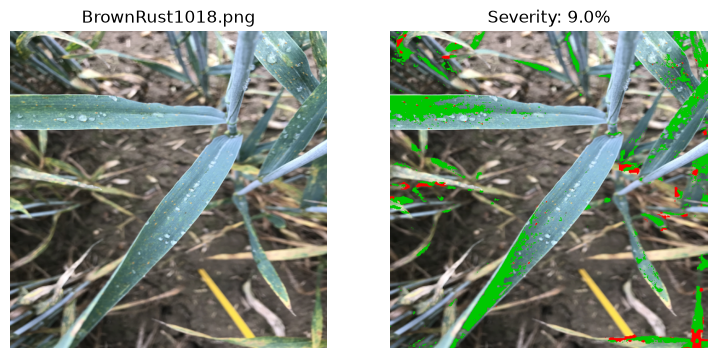

In [6]:
def show(path):
    sev, rgb, overlay = estimate_severity(path)
    fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
    ax[0].imshow(rgb); ax[0].set_title(Path(path).name); ax[0].axis("off")
    ax[1].imshow(overlay); ax[1].set_title(f"Severity: {sev:.1f}%"); ax[1].axis("off")
    plt.show()

RAW = Path(r"D:\AgriVision\data\raw")
for pattern in ["Healthy*.png", "YellowRust*.png", "BrownRust*.png"]:
    show(next(RAW.rglob(pattern)))

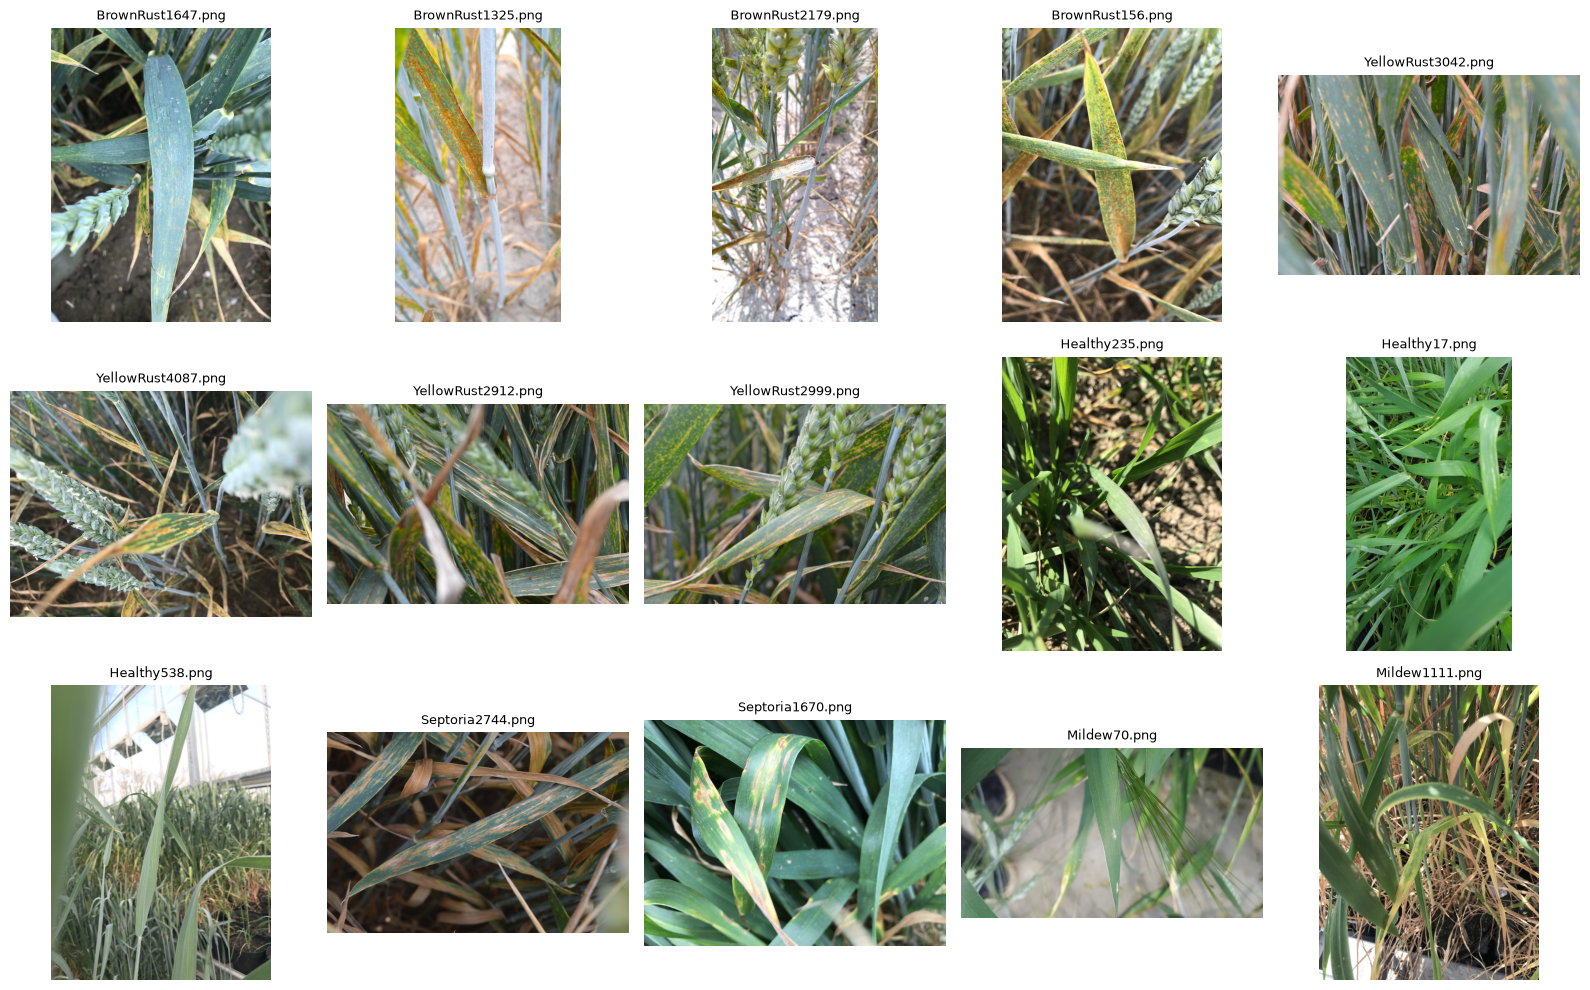

Copy this, then replace each 0 with your estimate:

manual = {
    "BrownRust1647.png": 0,
    "BrownRust1325.png": 0,
    "BrownRust2179.png": 0,
    "BrownRust156.png": 0,
    "YellowRust3042.png": 0,
    "YellowRust4087.png": 0,
    "YellowRust2912.png": 0,
    "YellowRust2999.png": 0,
    "Healthy235.png": 0,
    "Healthy17.png": 0,
    "Healthy538.png": 0,
    "Septoria2744.png": 0,
    "Septoria1670.png": 0,
    "Mildew70.png": 0,
    "Mildew1111.png": 0,
}


In [7]:
import random
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

RAW = Path(r"D:\AgriVision\data\raw")
random.seed(1)

picks = []
for prefix, n in [("BrownRust", 4), ("YellowRust", 4), ("Healthy", 3),
                  ("Septoria", 2), ("Mildew", 2)]:
    files = sorted(RAW.rglob(prefix + "*.png"))
    picks += random.sample(files, n)

fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for ax, p in zip(axes.flat, picks):
    ax.imshow(Image.open(p))
    ax.set_title(p.name, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Copy this, then replace each 0 with your estimate:\n")
print("manual = {")
for p in picks:
    print(f'    "{p.name}": 0,')
print("}")

In [8]:
manual = {
    "BrownRust1647.png": 3,
    "BrownRust1325.png": 5,
    "BrownRust2179.png": 6,
    "BrownRust156.png": 8,
    "YellowRust3042.png": 7,
    "YellowRust4087.png": 8,
    "YellowRust2912.png": 5,
    "YellowRust2999.png": 2,
    "Healthy235.png": 1,
    "Healthy17.png": 0,
    "Healthy538.png": 0,
    "Septoria2744.png": 9,
    "Septoria1670.png": 5,
    "Mildew70.png": 2,
    "Mildew1111.png": 10,
}

              file  manual_%  algorithm_%
 BrownRust1647.png         3         14.4
 BrownRust1325.png         5         53.4
 BrownRust2179.png         6         45.7
  BrownRust156.png         8         42.6
YellowRust3042.png         7         42.2
YellowRust4087.png         8         30.8
YellowRust2912.png         5         32.9
YellowRust2999.png         2         18.8
    Healthy235.png         1         10.6
     Healthy17.png         0          0.6
    Healthy538.png         0         12.6
  Septoria2744.png         9         40.4
  Septoria1670.png         5          2.1
      Mildew70.png         2          2.4
    Mildew1111.png        10         30.7
Correlation: 0.699
Mean absolute difference: 21.0


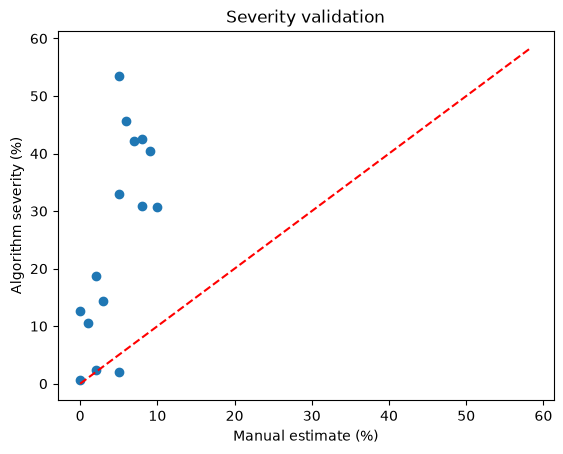

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAW = Path(r"D:\AgriVision\data\raw")

rows = []
for name, m in manual.items():
    p = next(RAW.rglob(name), None)
    if p is None:
        print("Not found:", name)
        continue
    sev, _, _ = estimate_severity(p)
    rows.append({"file": name, "manual_%": m, "algorithm_%": round(sev, 1)})

val = pd.DataFrame(rows)
print(val.to_string(index=False))
print("Correlation:", round(val["manual_%"].corr(val["algorithm_%"]), 3))
print("Mean absolute difference:", round((val["manual_%"] - val["algorithm_%"]).abs().mean(), 1))

lim = max(val["manual_%"].max(), val["algorithm_%"].max()) + 5
plt.scatter(val["manual_%"], val["algorithm_%"])
plt.plot([0, lim], [0, lim], "r--")
plt.xlabel("Manual estimate (%)")
plt.ylabel("Algorithm severity (%)")
plt.title("Severity validation")
plt.show()